In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
df= pd.read_csv("vehicles.csv")

/var/folders/jb/9m9w0dm52ps6xxz631ss34tm0000gn/T/ipykernel_2399/61321399.py:1: DtypeWarning: Columns (4,32,40) have mixed types. Specify dtype option on import or set low_memory=False.
  df= pd.read_csv("vehicles.csv")


# year vs price

In [3]:
df['year'].describe().round(2) 

count    295425.00
mean       2012.77
std          11.58
min        1900.00
25%        2010.00
50%        2015.00
75%        2019.00
max        2027.00
Name: year, dtype: float64

In [4]:
df['year'].value_counts().sort_index()

year
1900.0       14
1901.0        6
1902.0        1
1914.0        3
1917.0        1
          ...  
2023.0    10987
2024.0     9765
2025.0     7774
2026.0     4835
2027.0      535
Name: count, Length: 114, dtype: int64

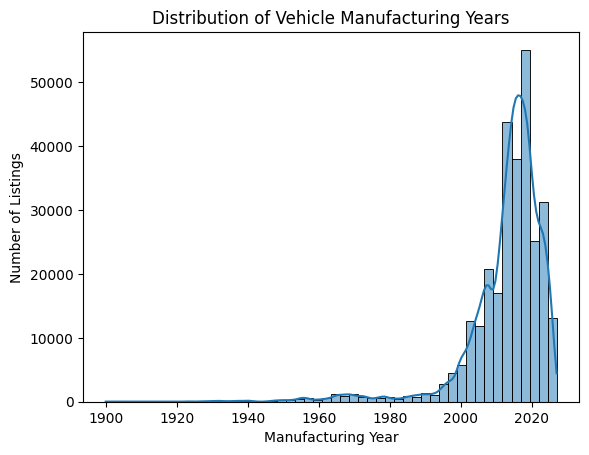

In [5]:
sns.histplot(
    df['year'].dropna(),
    bins=50,
    kde=True
)

plt.title('Distribution of Vehicle Manufacturing Years')
plt.xlabel('Manufacturing Year')
plt.ylabel('Number of Listings')

plt.show()

In [6]:
df.loc[
    df['year'] < 1950,
    ['year', 'manufacturer', 'model', 'price', 'title']
].head(5)

,year,manufacturer,model,price,title
779,1932.0,ford,t bucket,11000,Ford T bucket hot rod project
935,1923.0,ford,bucket-t,25000,1923 Ford Bucket‑T – Auto – 6692 Miles – Clean...
1608,1935.0,NaN,Studebaker Dictator,36995,1935 Studebaker Dictator 4DR ~ L@@K ~ What A C...
2073,1939.0,ford,1/2 ton pickup,19950,Vintage 1939 Ford 1/2 Ton Pickup
2099,1920.0,ford,model t,14000,Model T Speedster


In [7]:
df.loc[
    df['year'] >2026,
    ['year', 'manufacturer', 'model', 'price', 'title']
].head(5)

,year,manufacturer,model,price,title
456,2027.0,ford,expedition max platinum,1658,"2027 Ford Expedition Max Platinum FOR ONLY $1,..."
577,2027.0,toyota,corolla le,0,2027 Toyota Corolla LE sedan Ice Cap
583,2027.0,toyota,corolla le,0,2027 Toyota Corolla LE sedan Celestite
606,2027.0,toyota,camry se,0,2027 Toyota Camry SE sedan Supersonic Red <a
857,2027.0,ford,super duty f-350 srw xl,1092,2027 Ford Super Duty F350 F 350 F-350 SRW Supe...


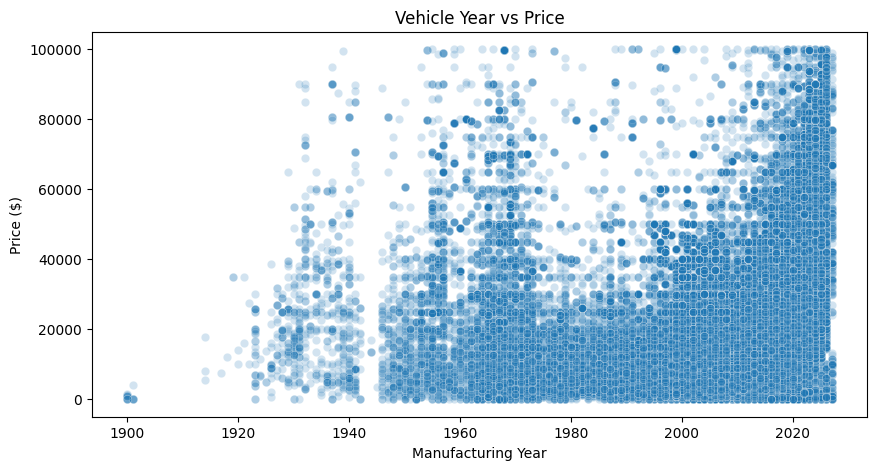

In [8]:
price_numeric=pd.to_numeric(df['price'],errors='coerce')

data=df.loc[
    (df['year'].notna())& (price_numeric>0)
].copy()
data['price']=price_numeric.loc[data.index]
data=data[data['price']<=100000]

plt.figure(figsize=(10, 5))
sns.scatterplot(data=data, x='year', y='price', alpha=0.2)

plt.title('Vehicle Year vs Price')
plt.xlabel('Manufacturing Year')
plt.ylabel('Price ($)')
plt.show()

In [9]:
data[['year', 'price']].corr()

,year,price
year,1.00000,0.19783
price,0.19783,1.00000


- Manufacturing year may help predict vehicle prices, but it is not sufficient on its own. Other features such as manufacturer, model, mileage and condition should also be investigated.

# odometer data quality check 

In [10]:
temp = df.copy()
temp['price_numeric'] = price_numeric
temp = temp[temp['price_numeric'] > 0]

plot_df = temp[(temp['price_numeric'] <= 100000) & (temp['odometer'] <= 500000)]

In [11]:
plot_df['odometer'].describe()

count    279036.000000
mean     111484.502964
std       61574.371417
min           1.000000
25%       69545.750000
50%      108881.000000
75%      148117.750000
max      500000.000000
Name: odometer, dtype: float64

<Axes: xlabel='odometer', ylabel='Count'>

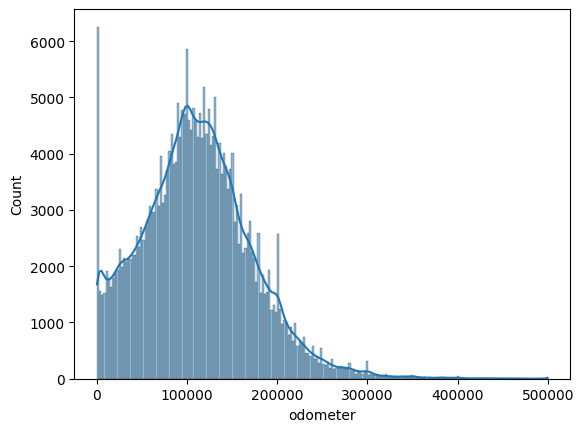

In [12]:
sns.histplot(plot_df['odometer'], kde=True)

In [13]:
plot_df['odometer'].skew()

np.float64(0.5930286925996151)

<Axes: ylabel='odometer'>

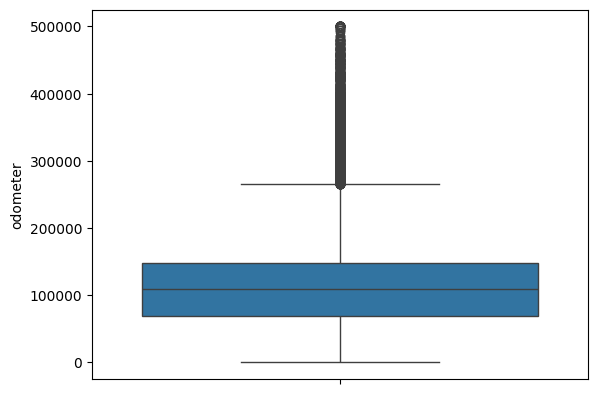

In [14]:
sns.boxplot(plot_df['odometer'])

<Axes: xlabel='odometer', ylabel='price_numeric'>

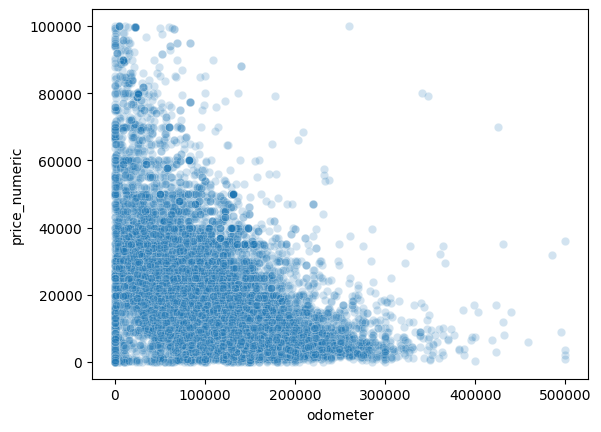

In [15]:
sample_df = plot_df.sample(20000, random_state=42)
sns.scatterplot(x=sample_df['odometer'], y=sample_df['price_numeric'], alpha=0.2)

In [16]:
plot_df[['odometer', 'price_numeric']].corr()

,odometer,price_numeric
odometer,1.000000,-0.482703
price_numeric,-0.482703,1.000000


In [17]:
plot_df[['year', 'odometer', 'price_numeric']].corr(method='spearman')

,year,odometer,price_numeric
year,1.000000,-0.431845,0.525797
odometer,-0.431845,1.000000,-0.543951
price_numeric,0.525797,-0.543951,1.000000


- Year’s Pearson correlation with price is only 0.19, but its Spearman correlation is 0.53. The relationship is strong but not linear, likely because vintage cars are old yet expensive. Odometer is similar under both measures (Pearson -0.48, Spearman -0.54). Year and odometer correlate at -0.43 with each other, so they’re related but each adds information.

# Duplicates

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df['id'].duplicated().sum()

np.int64(0)

In [29]:
df['VIN'].duplicated().sum()

np.int64(205357)

In [20]:
df['VIN'].value_counts().head(10)

VIN
1FTNW21FXYED30441    167
1FTHF26G7VEA77606    159
1B7KF26C6SS150366    150
1FTNW21F1YEA14829    131
1FTWX33F9YEA12508    130
1GYS4GKL2RR104604    126
1D7KS28C26J203560    121
3D7LX38C36G177354    121
1FTHX26F6TEA44954    121
1GKS2DKT2NR136641    120
Name: count, dtype: int64

In [21]:
df.duplicated(subset=['year', 'manufacturer', 'model', 'odometer', 'price', 'state']).sum()

np.int64(84843)

In [22]:
subset = ['year', 'manufacturer', 'model', 'odometer', 'price', 'state']
dups = df[df.duplicated(subset=subset, keep=False)]
len(dups)

126180

In [23]:
dups[subset].isnull().any(axis=1).sum()

np.int64(6870)

In [24]:
(dups['odometer'] < 100).sum()

np.int64(1523)

In [25]:
complete = df.dropna(subset=subset)
complete.duplicated(subset=subset).sum()

np.int64(80208)

In [26]:
df['VIN'].dropna().duplicated().sum()

np.int64(84239)

- There are cars which are posted more than once on list .
- About 80,208 rows have exact same year,brand ,model,mileage,price and state .
- About 84239 rows have a VIN (the car’s unique ID number) that already appeared earlier.
- that means our data have duplicates.

# Correlation Heatmap 

<Axes: >

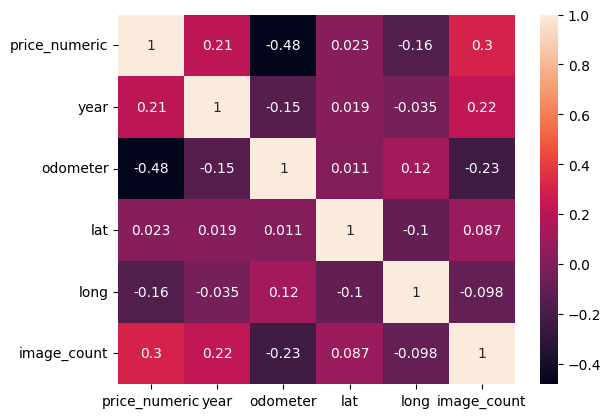

In [27]:
sns.heatmap(plot_df[['price_numeric', 'year', 'odometer', 'lat', 'long', 'image_count']].corr(),annot=True)

- We can see the negative correlation between the price and odometer . It means the cars with lower odometer value tend to have the higher price in general.

# Manufacturer vs Price 

In [30]:
temp=df.copy()

In [31]:
temp['price_numeric']= price_numeric
temp=temp[temp['price_numeric']>0]

In [33]:
temp['manufacturer'].isna().mean()*100

np.float64(3.6831566507576365)

In [35]:
temp['manufacturer'].nunique()

42

<Axes: xlabel='manufacturer'>

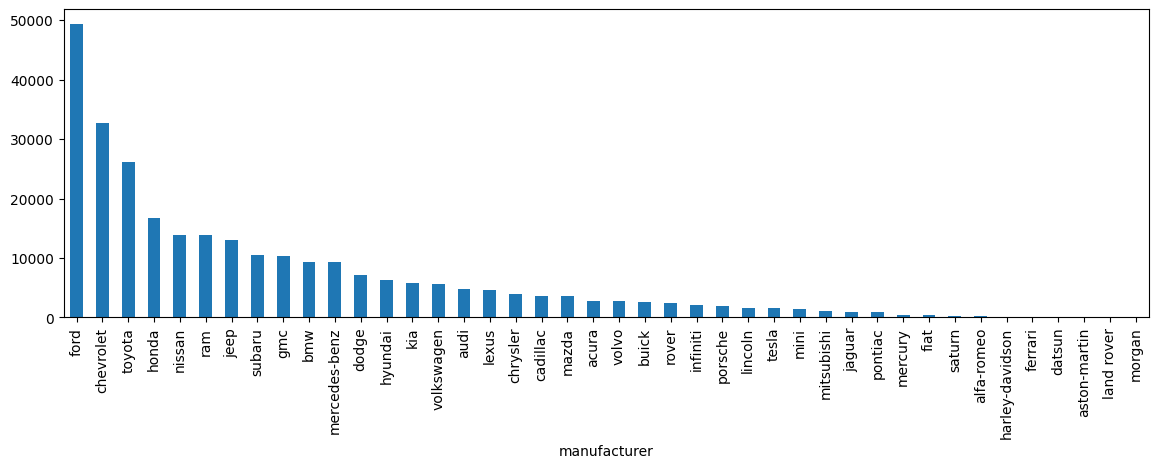

In [36]:
temp['manufacturer'].value_counts().plot(kind='bar', figsize=(14, 4))

In [37]:
counts= temp['manufacturer'].value_counts()
common=counts[counts >=500].index

brand_median = temp[temp['manufacturer'].isin(common)].groupby('manufacturer')['price_numeric'].median().sort_values(ascending=False)
brand_median

manufacturer
porsche          27034.0
ram              23500.0
tesla            21999.0
gmc              18995.0
rover            17200.0
ford             15500.0
toyota           14995.0
chevrolet        13995.0
mercedes-benz    13500.0
lexus            12995.0
cadillac         12995.0
jeep             12631.0
bmw              12500.0
honda            11995.0
audi             11980.5
jaguar           11900.0
volvo            11800.0
subaru           11490.5
mazda             9999.0
acura             9925.0
infiniti          9900.0
lincoln           9495.0
chrysler          9000.0
dodge             8995.0
volkswagen        8985.0
mitsubishi        8500.0
kia               8495.0
nissan            8450.0
hyundai           7995.0
mini              7981.0
buick             7736.0
pontiac           7500.0
Name: price_numeric, dtype: float64

<Axes: xlabel='manufacturer'>

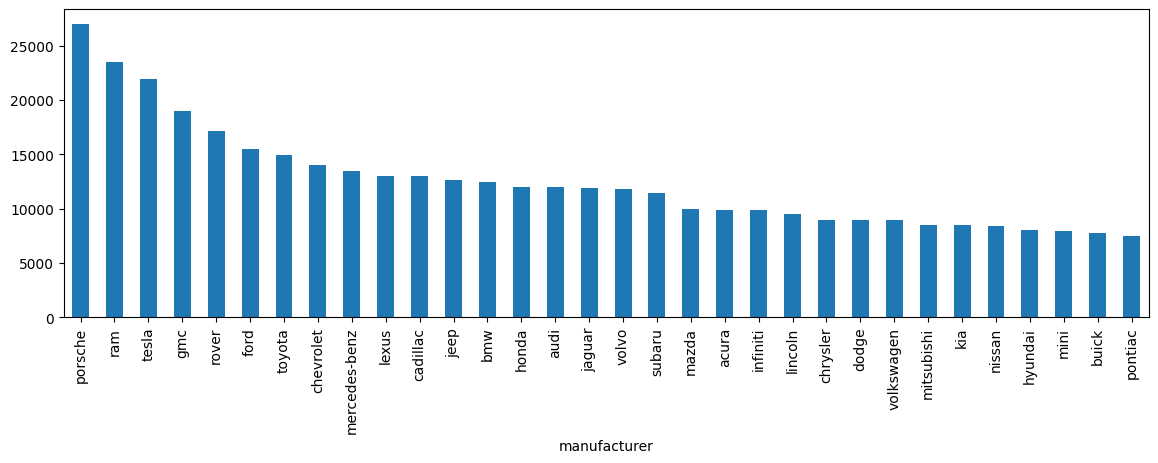

In [38]:
brand_median.plot(kind='bar',figsize=(14,4))

In [41]:
plot_df=temp[temp['price_numeric']<=100000]
top10= temp['manufacturer'].value_counts().head(10).index
top10_df= plot_df[plot_df['manufacturer'].isin(top10)]
# top10_df

<Axes: xlabel='manufacturer', ylabel='price_numeric'>

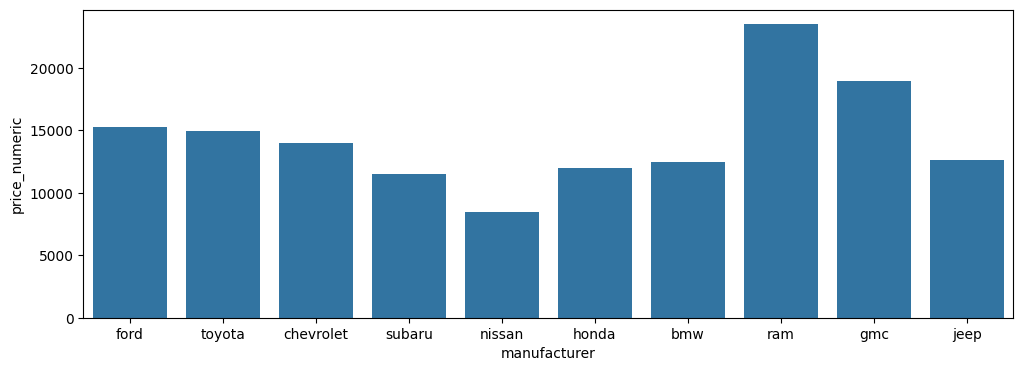

In [42]:
plt.figure(figsize=(12, 4))
sns.barplot(x=top10_df['manufacturer'], y=top10_df['price_numeric'], estimator='median', errorbar=None)

<Axes: xlabel='manufacturer', ylabel='price_numeric'>

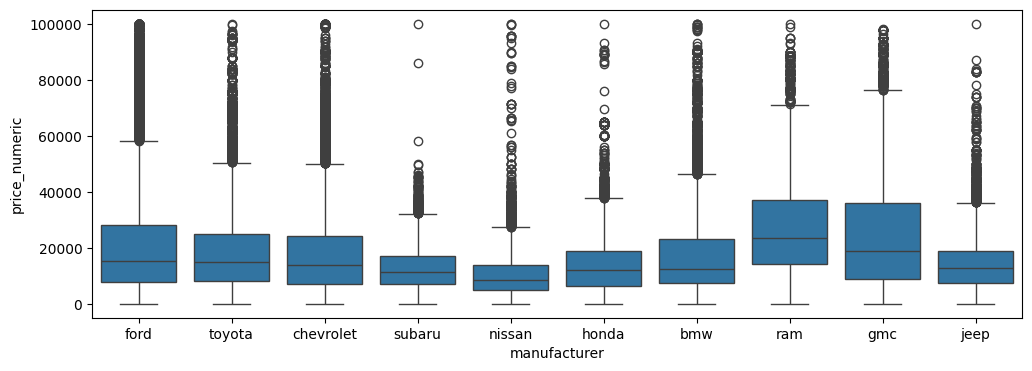

In [43]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=top10_df['manufacturer'], y=top10_df['price_numeric'])

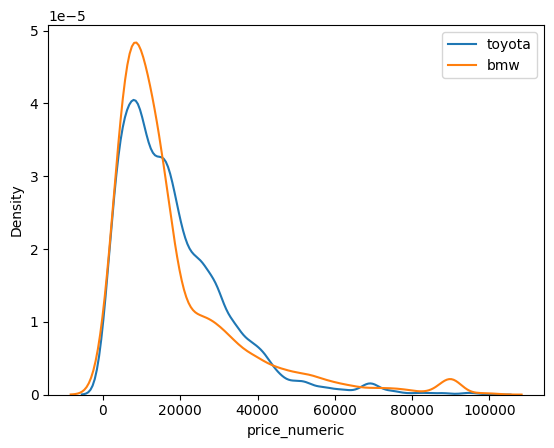

In [44]:
sns.kdeplot(plot_df[plot_df['manufacturer'] == 'toyota']['price_numeric'], label='toyota')
sns.kdeplot(plot_df[plot_df['manufacturer'] == 'bmw']['price_numeric'], label='bmw')
plt.legend()

In [45]:
temp[temp['manufacturer'].isin(top10)].groupby('manufacturer')['year'].median().sort_values()

manufacturer
toyota       2014.0
bmw          2015.0
chevrolet    2015.0
ford         2015.0
honda        2015.0
jeep         2016.0
nissan       2016.0
subaru       2016.0
gmc          2017.0
ram          2017.0
Name: year, dtype: float64

In [46]:
same_age = temp[(temp['manufacturer'].isin(top10)) & (temp['year'].between(2015, 2017))]
same_age.groupby('manufacturer')['price_numeric'].median().sort_values(ascending=False)

manufacturer
ram          18500.0
toyota       16995.0
gmc          15455.0
ford         14000.0
honda        12999.0
bmw          12750.0
chevrolet    11999.0
subaru       10999.0
jeep         10995.0
nissan        7995.0
Name: price_numeric, dtype: float64

- Top 10 common cars are analysed .
- Ram (18500) and toyota (16995) have the highest median prices when their vehicles of same age were tested and the nissan have the lowest .
- BMW is also seen 6th in median prices of same age that signals the luxury brands depreciate faster than the other brands when used .
- Price overlaps a lot between the brands so, I can't alone determine the price with the brands .

# Model vs price

In [48]:
temp['model'].isna().mean()*100

np.float64(1.1533754379074426)

In [51]:
temp['model'].nunique()

27331

In [52]:
temp['model'].str.lower().str.strip().nunique()

26568

In [53]:
model_counts= temp['model'].value_counts()
model_counts.head(15)

model
f-150             4151
1500              2686
silverado 1500    2353
civic             2039
camry             2030
outback           2018
accord            2015
forester          1975
2500              1831
wrangler          1747
tacoma            1724
f-250             1589
altima            1552
escape            1518
rogue             1499
Name: count, dtype: int64

In [55]:
(model_counts==1).sum()

np.int64(14407)

In [57]:
(model_counts >= 100).sum()

np.int64(422)

In [58]:
model_counts.head(100).sum() / model_counts.sum()

np.float64(0.32539006790267994)

In [59]:
model_counts.head(500).sum() / model_counts.sum()

np.float64(0.5650467939575838)

In [60]:
base_model = temp['model'].str.lower().str.strip().str.split().str[0]
base_model.nunique()

4037

In [61]:
base_model.value_counts().head(20)

model
silverado    8888
f-150        6864
1500         5594
grand        5137
wrangler     4937
sierra       4882
civic        4002
f-250        3986
2500         3963
accord       3851
tacoma       3823
f-350        3586
camry        3544
transit      3394
explorer     3129
escape       3004
forester     2958
outback      2916
f150         2779
rogue        2627
Name: count, dtype: int64

In [62]:
base_model.value_counts().head(500).sum() / base_model.value_counts().sum()

np.float64(0.9356698382965438)

In [63]:
base_model.value_counts().head(30)

model
silverado    8888
f-150        6864
1500         5594
grand        5137
wrangler     4937
sierra       4882
civic        4002
f-250        3986
2500         3963
accord       3851
tacoma       3823
f-350        3586
camry        3544
transit      3394
explorer     3129
escape       3004
forester     2958
outback      2916
f150         2779
rogue        2627
corolla      2616
rav4         2590
sienna       2509
equinox      2443
altima       2425
mustang      2266
express      2255
cr-v         2155
tundra       2144
corvette     2048
Name: count, dtype: int64

In [64]:
temp[base_model == '1500']['manufacturer'].value_counts()

manufacturer
ram          5496
chevrolet      54
gmc            20
dodge           3
fiat            1
ford            1
Name: count, dtype: int64

In [65]:
top20 = base_model.value_counts().head(20).index
temp[base_model.isin(top20)].groupby(base_model)['price_numeric'].median().sort_values(ascending=False)

model
f-350        37900.0
2500         34900.0
f-250        30800.0
sierra       29995.0
tacoma       22995.0
transit      19999.0
silverado    19970.0
f-150        17995.0
1500         16900.0
wrangler     15995.0
f150         13995.0
civic        12995.0
explorer     10970.0
grand        10500.0
outback      10499.0
forester     10479.0
accord       10000.0
camry         9495.0
rogue         8999.0
escape        7800.0
Name: price_numeric, dtype: float64

- Model matters a lot: big trucks (F-350, Ram 2500) cost around $35k, while small cars (Camry, Escape) cost under 10k.
- The model names are messy, but using just the first word (like "silverado") covers 93% of cars. Spellings like "f-150" and "f150" still need fixing.
- Model explains part of the brand difference. Toyota looks expensive mainly because of its trucks, like the Tacoma.